In [180]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler, StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
import re

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

In [181]:
df = pd.read_csv("https://drive.google.com/uc?export=download&id=1D5gl2EZtevQCf9AgRR3MWtkmOefu_qnd")

In [182]:
df = df.drop(columns = ["Unnamed: 0"])

In [183]:
df.head()

,Country,Region,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,...,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Economy_status_Developed,Economy_status_Developing,Life_expectancy
0,Turkiye,Middle East,2015,11.1,13.0,105.8240,1.32,97,65,27.8,...,97,0.08,11006,78.53,4.9,4.8,7.8,0,1,76.5
1,Spain,European Union,2015,2.7,3.3,57.9025,10.35,97,94,26.0,...,97,0.09,25742,46.44,0.6,0.5,9.7,1,0,82.8
2,India,Asia,2007,51.5,67.9,201.0765,1.57,60,35,21.2,...,64,0.13,1076,1183.21,27.1,28.0,5.0,0,1,65.4
3,Guyana,South America,2006,32.8,40.5,222.1965,5.68,93,74,25.3,...,93,0.79,4146,0.75,5.7,5.5,7.9,0,1,67.0
4,Palestine,Middle East,2012,3.4,4.3,57.9510,2.89,97,89,27.0,...,94,0.08,33995,7.91,1.2,1.1,12.8,1,0,81.7


In [184]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2864 entries, 0 to 2863
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Country                      2864 non-null   object 
 1   Region                       2864 non-null   object 
 2   Year                         2864 non-null   int64  
 3   Infant_deaths                2864 non-null   float64
 4   Under_five_deaths            2864 non-null   float64
 5   Adult_mortality              2864 non-null   float64
 6   Alcohol_consumption          2864 non-null   float64
 7   Hepatitis_B                  2864 non-null   int64  
 8   Measles                      2864 non-null   int64  
 9   BMI                          2864 non-null   float64
 10  Polio                        2864 non-null   int64  
 11  Diphtheria                   2864 non-null   int64  
 12  Incidents_HIV                2864 non-null   float64
 13  GDP_per_capita    

In [185]:
df.shape

(2864, 21)

In [186]:
df.describe()

,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,Polio,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Economy_status_Developed,Economy_status_Developing,Life_expectancy
count,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000,2864.000000
mean,2007.500000,30.363792,42.938268,192.251775,4.820882,84.292598,77.344972,25.032926,86.499651,86.271648,0.894288,11540.924930,36.675915,4.865852,4.899825,7.632123,0.206704,0.793296,68.856075
std,4.610577,27.538117,44.569974,114.910281,3.981949,15.995511,18.659693,2.193905,15.080365,15.534225,2.381389,16934.788931,136.485867,4.438234,4.525217,3.171556,0.405012,0.405012,9.405608
min,2000.000000,1.800000,2.300000,49.384000,0.000000,12.000000,10.000000,19.800000,8.000000,16.000000,0.010000,148.000000,0.080000,0.100000,0.100000,1.100000,0.000000,0.000000,39.400000
25%,2003.750000,8.100000,9.675000,106.910250,1.200000,78.000000,64.000000,23.200000,81.000000,81.000000,0.080000,1415.750000,2.097500,1.600000,1.600000,5.100000,0.000000,1.000000,62.700000
50%,2007.500000,19.600000,23.100000,163.841500,4.020000,89.000000,83.000000,25.500000,93.000000,93.000000,0.150000,4217.000000,7.850000,3.300000,3.400000,7.800000,0.000000,1.000000,71.400000
75%,2011.250000,47.350000,66.000000,246.791375,7.777500,96.000000,93.000000,26.400000,97.000000,97.000000,0.460000,12557.000000,23.687500,7.200000,7.300000,10.300000,0.000000,1.000000,75.400000
max,2015.000000,138.100000,224.900000,719.360500,17.870000,99.000000,99.000000,32.100000,99.000000,99.000000,21.680000,112418.000000,1379.860000,27.700000,28.600000,14.100000,1.000000,1.000000,83.800000


# Data Cleaning

## Feature Engineering

# Normalising Feature Names

In [187]:
df.rename(columns= {"Economy_status_Developed" : "economic_status"}, inplace = True)
df.head()

,Country,Region,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,...,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,economic_status,Economy_status_Developing,Life_expectancy
0,Turkiye,Middle East,2015,11.1,13.0,105.8240,1.32,97,65,27.8,...,97,0.08,11006,78.53,4.9,4.8,7.8,0,1,76.5
1,Spain,European Union,2015,2.7,3.3,57.9025,10.35,97,94,26.0,...,97,0.09,25742,46.44,0.6,0.5,9.7,1,0,82.8
2,India,Asia,2007,51.5,67.9,201.0765,1.57,60,35,21.2,...,64,0.13,1076,1183.21,27.1,28.0,5.0,0,1,65.4
3,Guyana,South America,2006,32.8,40.5,222.1965,5.68,93,74,25.3,...,93,0.79,4146,0.75,5.7,5.5,7.9,0,1,67.0
4,Palestine,Middle East,2012,3.4,4.3,57.9510,2.89,97,89,27.0,...,94,0.08,33995,7.91,1.2,1.1,12.8,1,0,81.7


In [188]:
df.columns.tolist()

['Country',
 'Region',
 'Year',
 'Infant_deaths',
 'Under_five_deaths',
 'Adult_mortality',
 'Alcohol_consumption',
 'Hepatitis_B',
 'Measles',
 'BMI',
 'Polio',
 'Diphtheria',
 'Incidents_HIV',
 'GDP_per_capita',
 'Population_mln',
 'Thinness_ten_nineteen_years',
 'Thinness_five_nine_years',
 'Schooling',
 'economic_status',
 'Economy_status_Developing',
 'Life_expectancy']

In [189]:
df.columns = df.columns.str.lower().str.strip()


In [190]:
df.columns.tolist()

['country',
 'region',
 'year',
 'infant_deaths',
 'under_five_deaths',
 'adult_mortality',
 'alcohol_consumption',
 'hepatitis_b',
 'measles',
 'bmi',
 'polio',
 'diphtheria',
 'incidents_hiv',
 'gdp_per_capita',
 'population_mln',
 'thinness_ten_nineteen_years',
 'thinness_five_nine_years',
 'schooling',
 'economic_status',
 'economy_status_developing',
 'life_expectancy']

In [191]:
df["thinness_five_nineteen_years"] = round(((df["thinness_ten_nineteen_years"] + df["thinness_five_nine_years"]) / 2), 2)

In [192]:
df.head()

,country,region,year,infant_deaths,under_five_deaths,adult_mortality,alcohol_consumption,hepatitis_b,measles,bmi,...,incidents_hiv,gdp_per_capita,population_mln,thinness_ten_nineteen_years,thinness_five_nine_years,schooling,economic_status,economy_status_developing,life_expectancy,thinness_five_nineteen_years
0,Turkiye,Middle East,2015,11.1,13.0,105.8240,1.32,97,65,27.8,...,0.08,11006,78.53,4.9,4.8,7.8,0,1,76.5,4.85
1,Spain,European Union,2015,2.7,3.3,57.9025,10.35,97,94,26.0,...,0.09,25742,46.44,0.6,0.5,9.7,1,0,82.8,0.55
2,India,Asia,2007,51.5,67.9,201.0765,1.57,60,35,21.2,...,0.13,1076,1183.21,27.1,28.0,5.0,0,1,65.4,27.55
3,Guyana,South America,2006,32.8,40.5,222.1965,5.68,93,74,25.3,...,0.79,4146,0.75,5.7,5.5,7.9,0,1,67.0,5.60
4,Palestine,Middle East,2012,3.4,4.3,57.9510,2.89,97,89,27.0,...,0.08,33995,7.91,1.2,1.1,12.8,1,0,81.7,1.15


In [193]:
df = df.drop(columns = ["economy_status_developing", "thinness_ten_nineteen_years", "thinness_five_nine_years"])

In [194]:
df.isnull().sum()

country                         0
region                          0
year                            0
infant_deaths                   0
under_five_deaths               0
adult_mortality                 0
alcohol_consumption             0
hepatitis_b                     0
measles                         0
bmi                             0
polio                           0
diphtheria                      0
incidents_hiv                   0
gdp_per_capita                  0
population_mln                  0
schooling                       0
economic_status                 0
life_expectancy                 0
thinness_five_nineteen_years    0
dtype: int64

In [195]:
df.duplicated().sum()

np.int64(0)

In [196]:
numeric_columns = list(df.select_dtypes(include = ["number"]).columns)
numeric_columns.remove("economic_status")

In [197]:
numeric_columns

['year',
 'infant_deaths',
 'under_five_deaths',
 'adult_mortality',
 'alcohol_consumption',
 'hepatitis_b',
 'measles',
 'bmi',
 'polio',
 'diphtheria',
 'incidents_hiv',
 'gdp_per_capita',
 'population_mln',
 'schooling',
 'life_expectancy',
 'thinness_five_nineteen_years']

In [198]:
len(numeric_columns)

16

In [199]:
import matplotlib.pyplot as plt
import seaborn as sns


def plot_numeric_boxplots(df, numeric_columns):
    fig, axes = plt.subplots(8,2, figsize=(16,30)) 
    axes = axes.flatten()

    colour_palette = ["#0B132B","#1C46C0","#00E5FF","#6A67CE","#FF4FD8"]

    for feature in range(len(numeric_columns)):
        sns.boxplot(
            x=df[numeric_columns[feature]],
            ax=axes[feature],
            color=colour_palette[(feature // 2) % len(colour_palette)])  # cycles back to the first colour
        axes[feature].set_xlabel(numeric_columns[feature].replace("_", " ").title(),fontweight="bold") # for presentation purposes!

    # fig.delaxes(axes[-1]) # 17 features 18 graphs, this deletes that extra graph

    plt.suptitle("Plot of Numeric Features\n\n", fontweight="bold", fontsize=24)
    plt.tight_layout()
    plt.show()

## Plot Exploring Outliers Within Each Numeric Feature

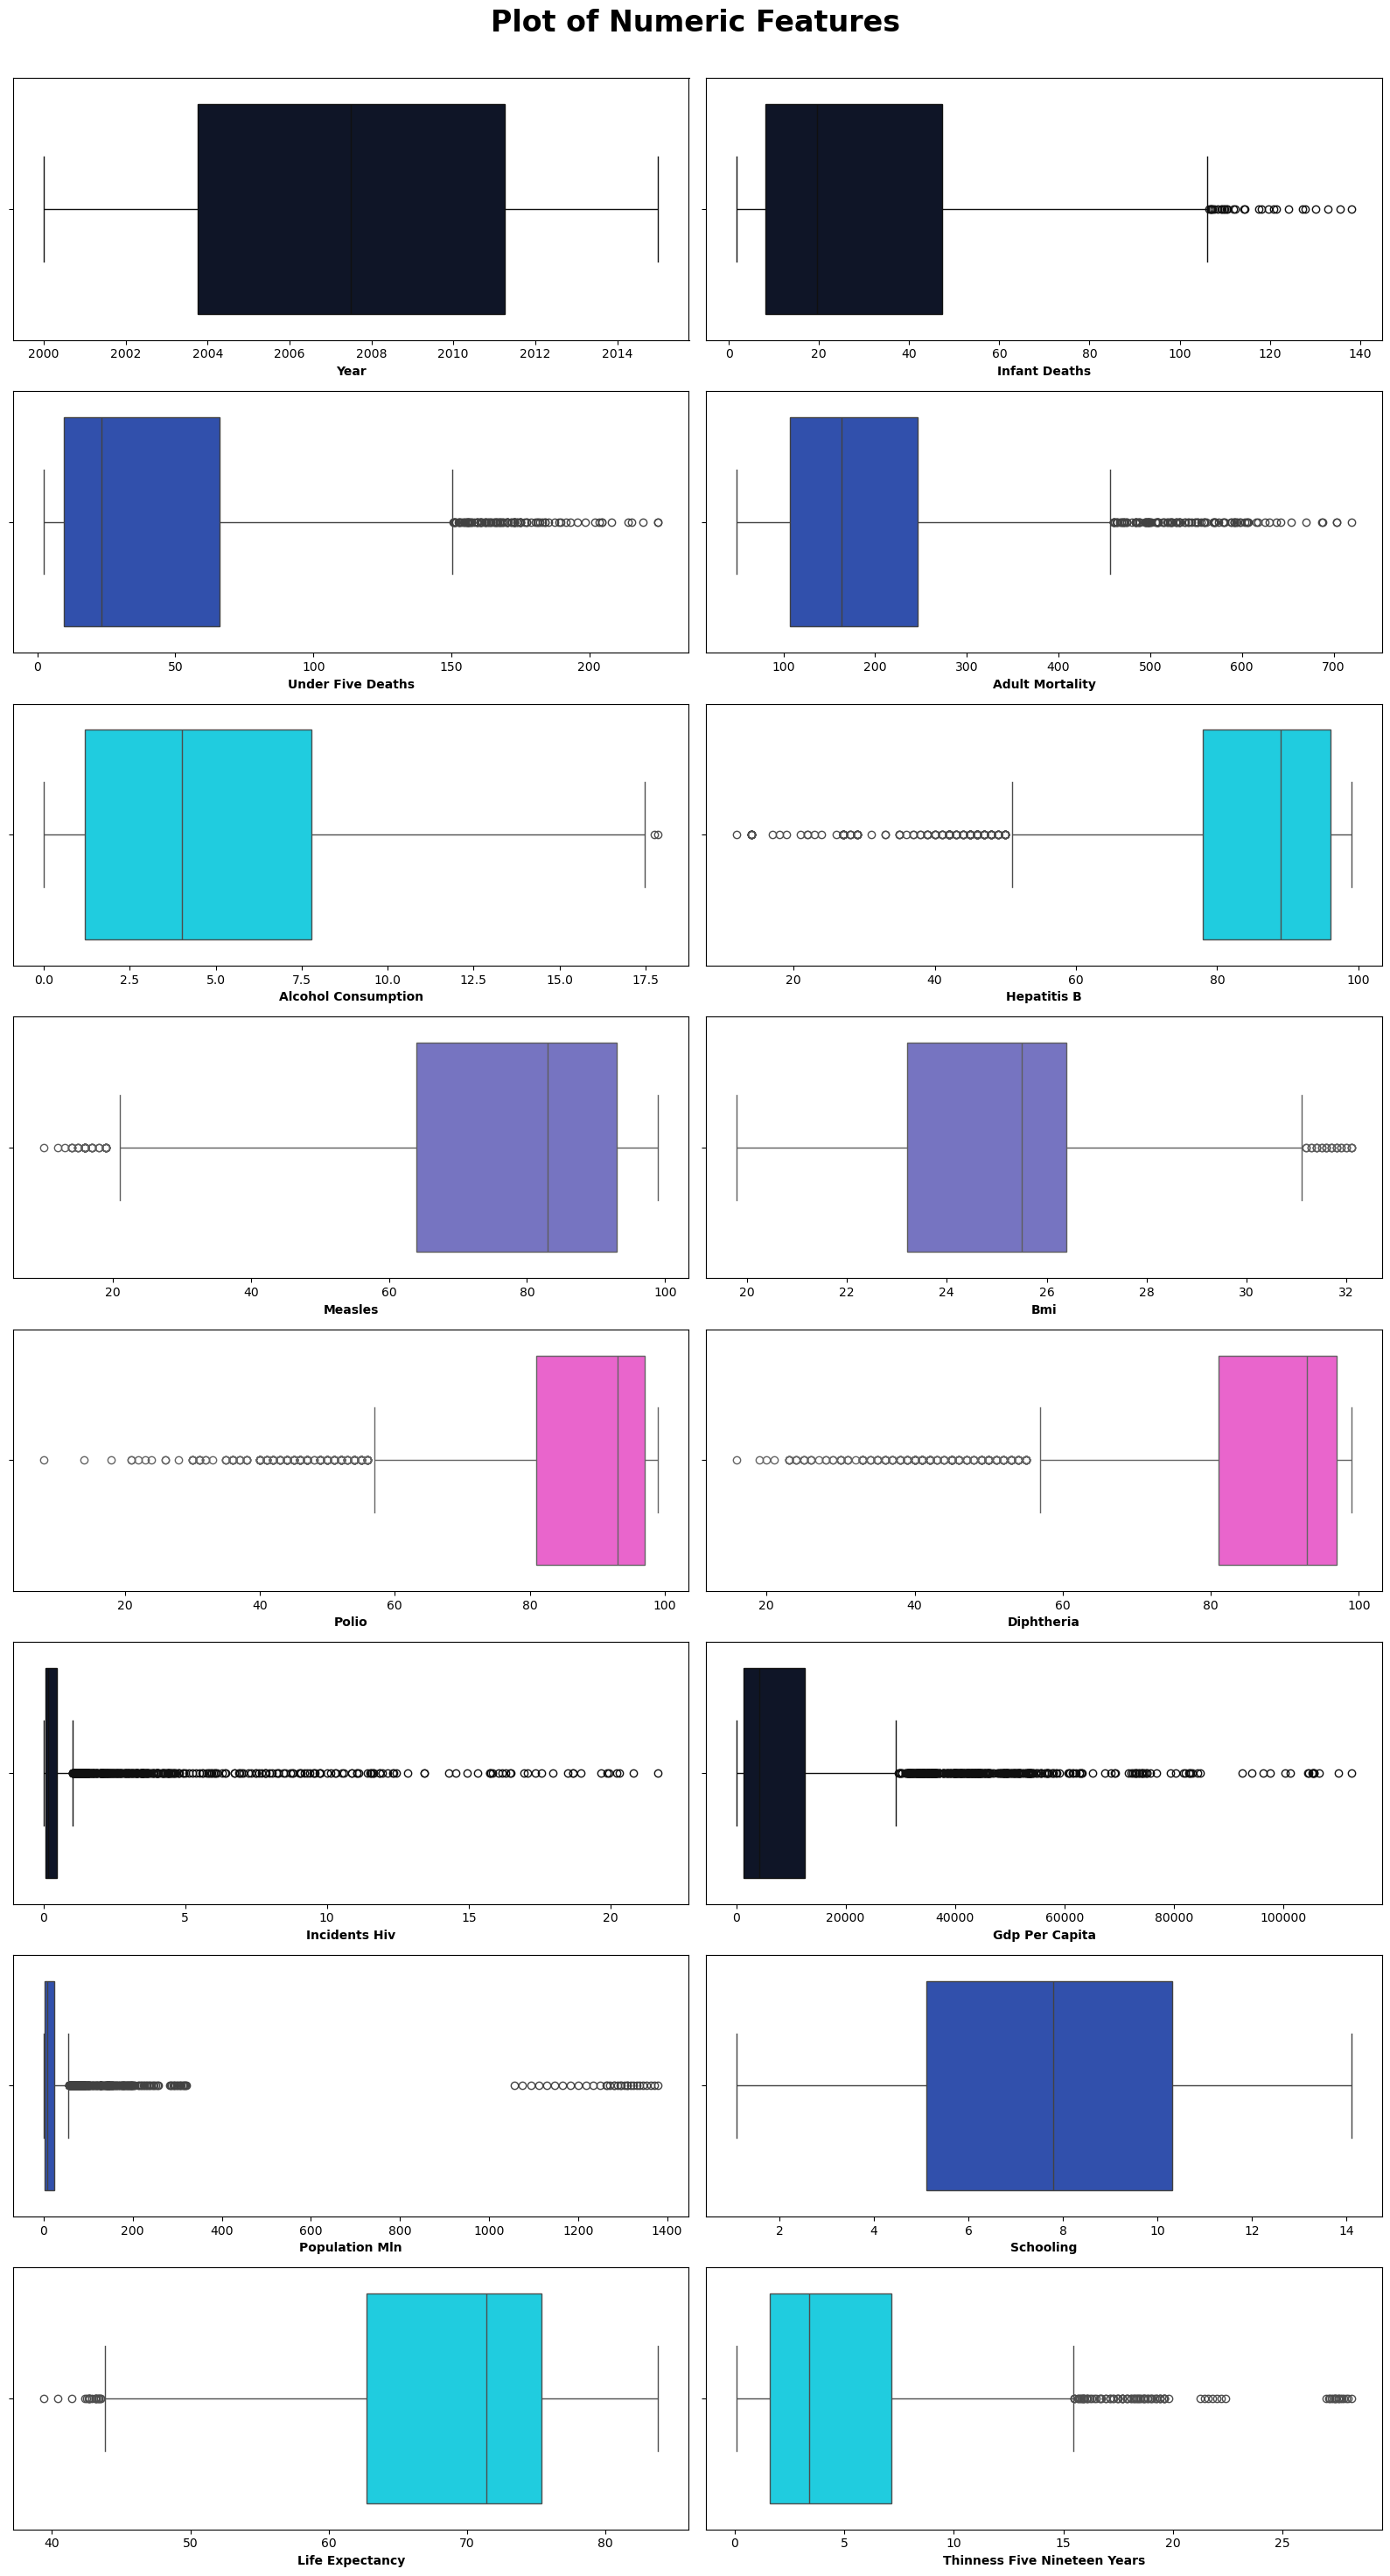

In [200]:
plot_numeric_boxplots(df, numeric_columns)

## Winsorisation -- outlier capping

In [201]:
def cap_outliers(df, numeric_columns):
    df_clean = df.copy()

    for column in numeric_columns:
        Q1 = df_clean[column].quantile(0.25)
        Q3 = df_clean[column].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        df_clean[column] = df_clean[column].clip(lower_bound, upper_bound)

    return df_clean

In [202]:
df = cap_outliers(df, numeric_columns)

## Plot After Clipping Outliers

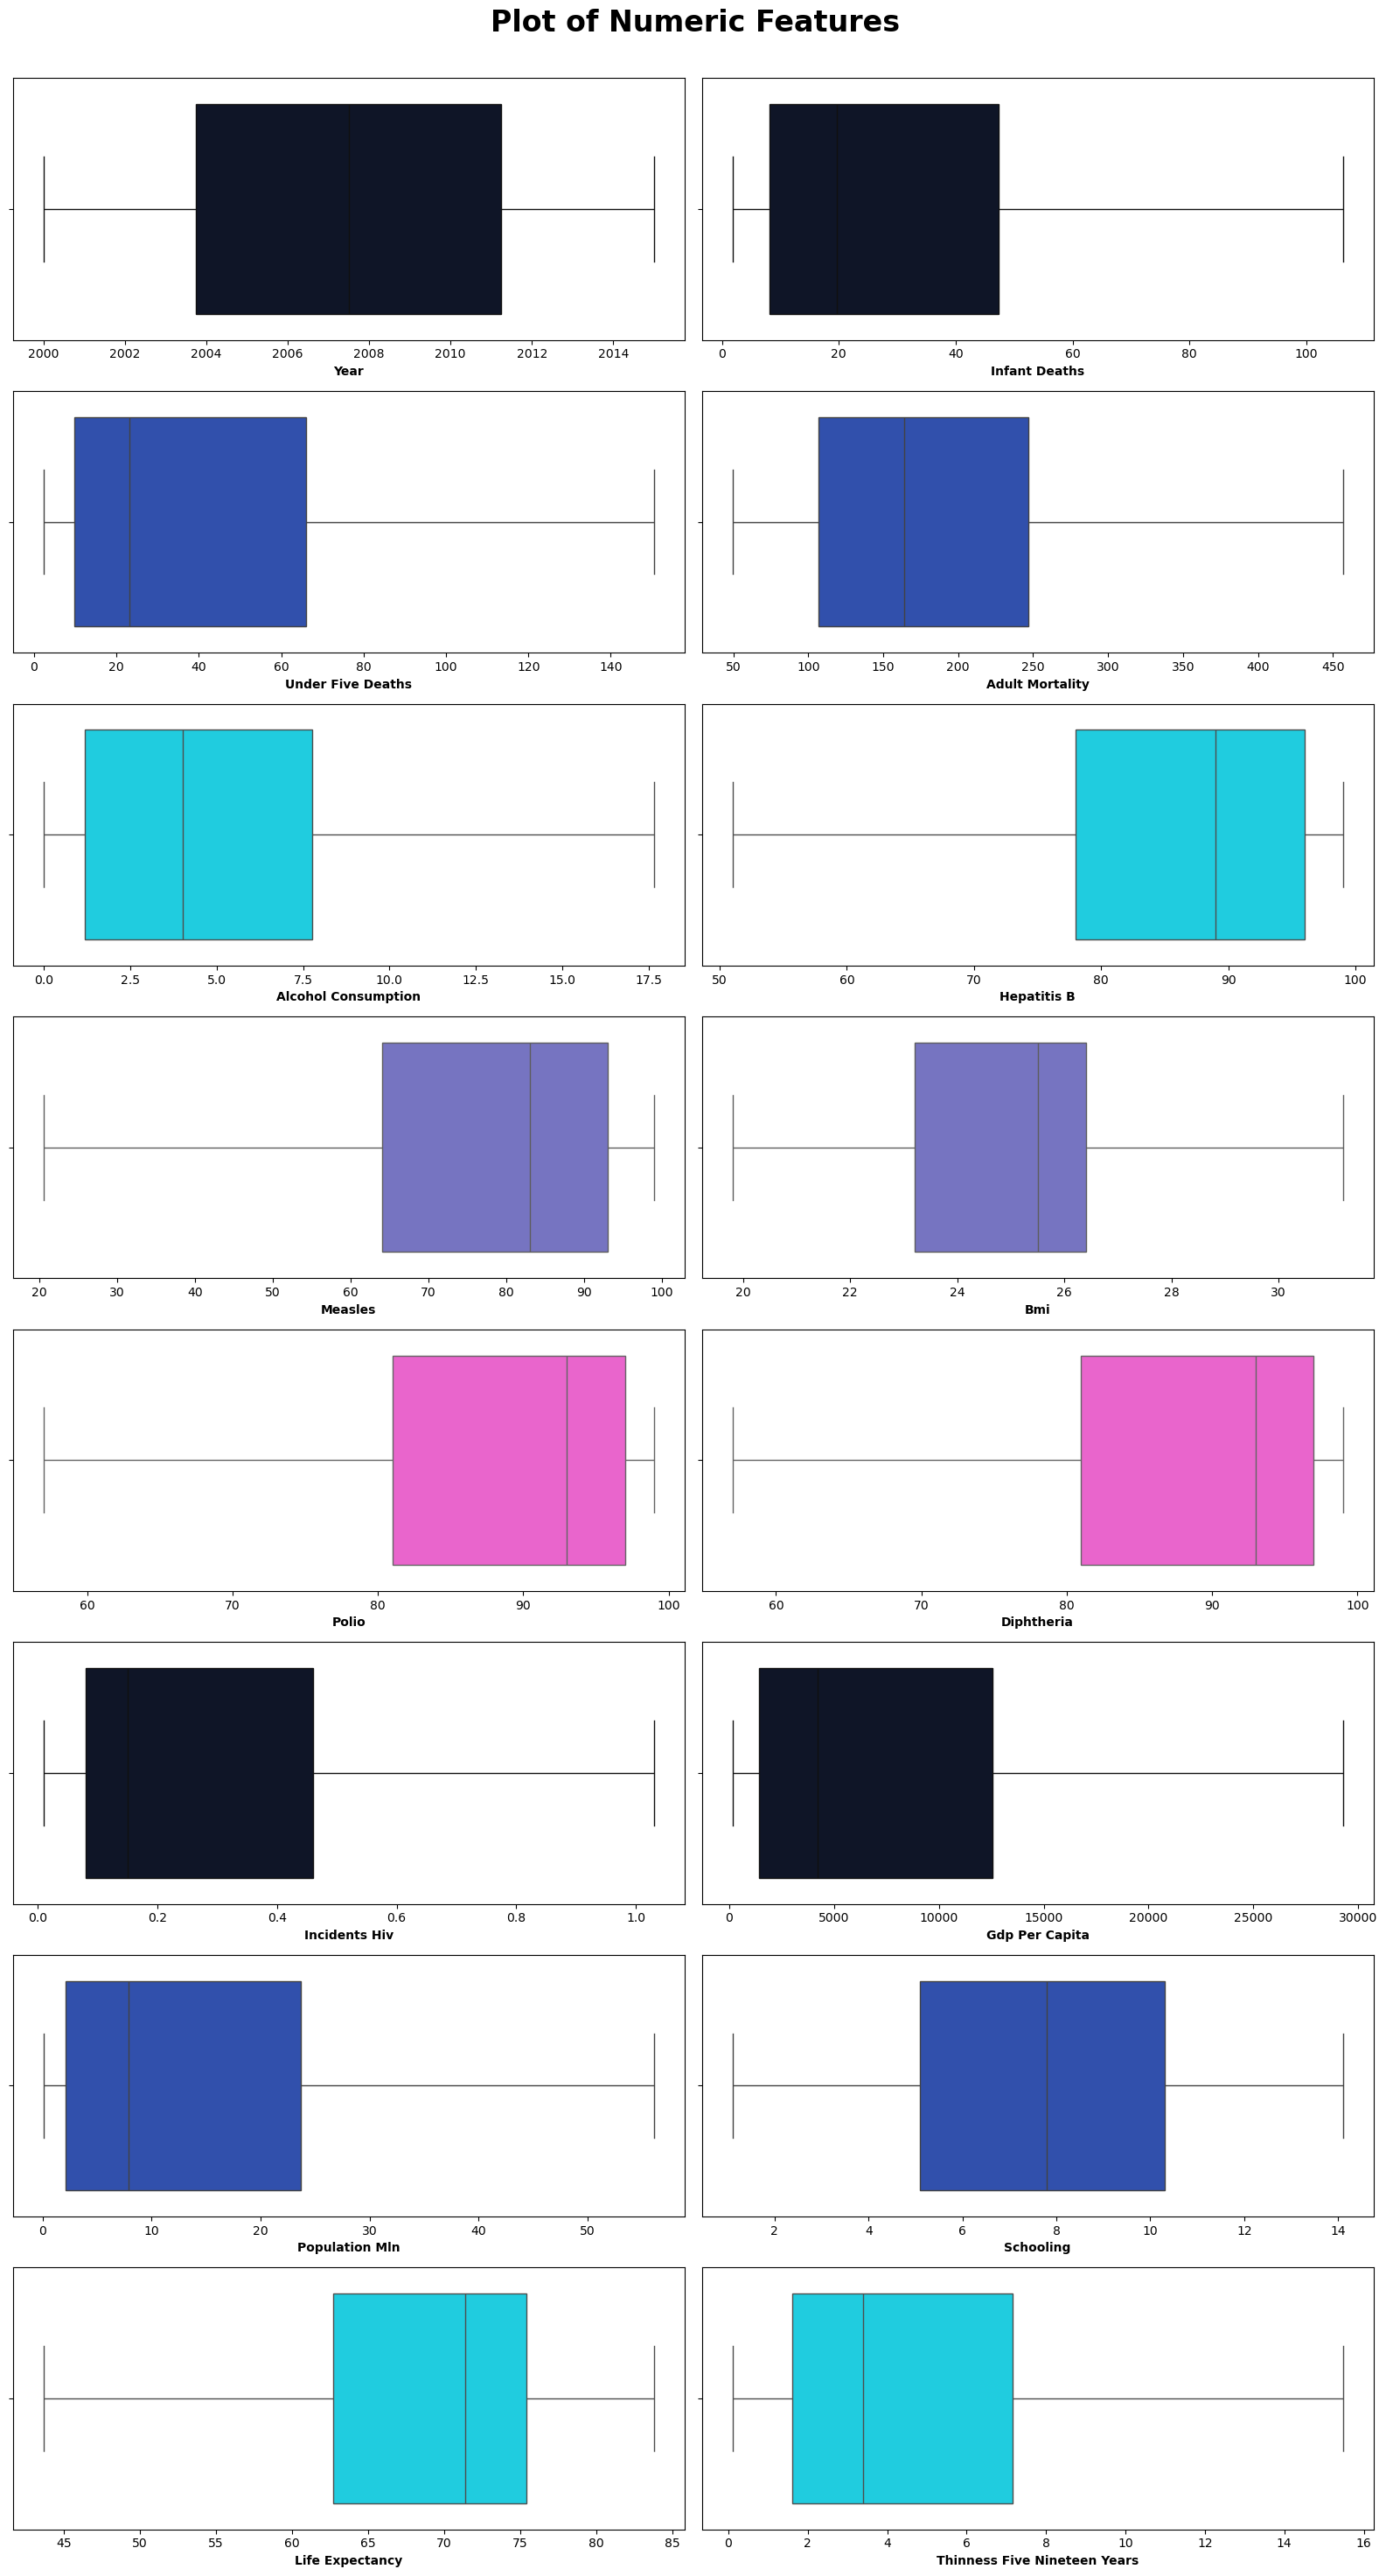

In [203]:
plot_numeric_boxplots(df, numeric_columns)

In [204]:
df_eda = df.copy()
df_eda = df_eda.drop(columns = ["country", "region"])

In [205]:
df_eda.corr()

,year,infant_deaths,under_five_deaths,adult_mortality,alcohol_consumption,hepatitis_b,measles,bmi,polio,diphtheria,incidents_hiv,gdp_per_capita,population_mln,schooling,economic_status,life_expectancy,thinness_five_nineteen_years
year,1.000000e+00,-0.170177,-0.166455,-0.150320,-0.000615,0.181768,0.085711,0.160932,0.131783,0.143297,-0.088923,0.047552,0.035825,0.150539,-5.026601e-15,0.173974,-0.048056
infant_deaths,-1.701768e-01,1.000000,0.988643,0.826786,-0.458817,-0.545035,-0.533202,-0.667491,-0.741033,-0.728754,0.636000,-0.620617,0.019825,-0.792289,-4.795688e-01,-0.921565,0.525920
under_five_deaths,-1.664549e-01,0.988643,1.000000,0.839570,-0.420714,-0.537151,-0.529545,-0.676668,-0.734513,-0.722377,0.659434,-0.585277,0.014431,-0.784624,-4.402333e-01,-0.929376,0.515597
adult_mortality,-1.503200e-01,0.826786,0.839570,1.000000,-0.256996,-0.385523,-0.442207,-0.553675,-0.562721,-0.552859,0.771852,-0.624387,-0.019997,-0.613895,-4.533406e-01,-0.957296,0.446878
alcohol_consumption,-6.152416e-04,-0.458817,-0.420714,-0.256996,1.000000,0.196041,0.320519,0.287230,0.320788,0.335449,-0.121662,0.507631,-0.014555,0.615743,6.703724e-01,0.399821,-0.468282
hepatitis_b,1.817683e-01,-0.545035,-0.537151,-0.385523,0.196041,1.000000,0.465741,0.372079,0.767478,0.794716,-0.259440,0.238359,-0.143600,0.374965,1.358213e-01,0.445462,-0.217513
measles,8.571051e-02,-0.533202,-0.529545,-0.442207,0.320519,0.465741,1.000000,0.421052,0.551938,0.539249,-0.346306,0.393609,-0.202098,0.501895,2.999631e-01,0.494463,-0.345880
bmi,1.609325e-01,-0.667491,-0.676668,-0.553675,0.287230,0.372079,0.421052,1.000000,0.465548,0.440879,-0.399977,0.431343,-0.205765,0.637367,2.455738e-01,0.601991,-0.629933
polio,1.317833e-01,-0.741033,-0.734513,-0.562721,0.320788,0.767478,0.551938,0.465548,1.000000,0.960179,-0.431181,0.406584,-0.047695,0.571345,3.011797e-01,0.646596,-0.340483
diphtheria,1.432975e-01,-0.728754,-0.722377,-0.552859,0.335449,0.794716,0.539249,0.440879,0.960179,1.000000,-0.416036,0.416507,-0.046530,0.561852,3.139806e-01,0.639679,-0.332860


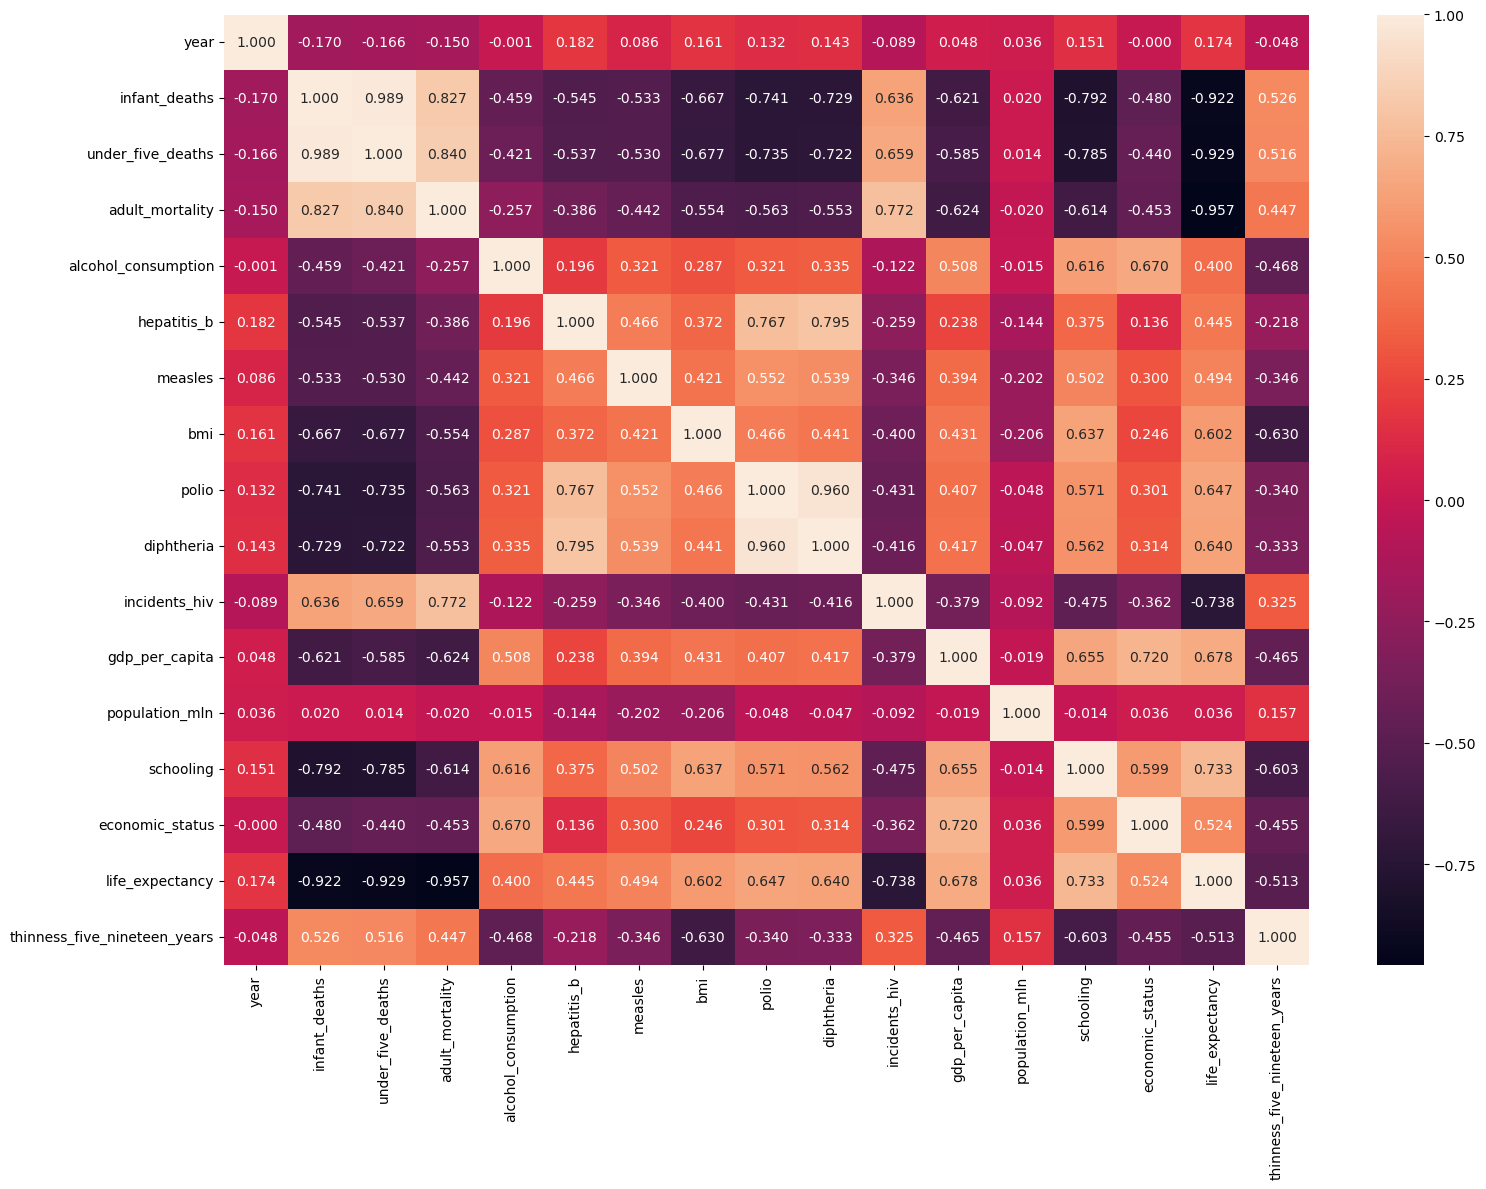

In [206]:
plt.figure(figsize = (16, 12))
sns.heatmap(df_eda.corr(), annot = True, fmt = ".3f")
plt.tight_layout()
plt.show()

Text(0.5, 0, 'Life Expectancy')

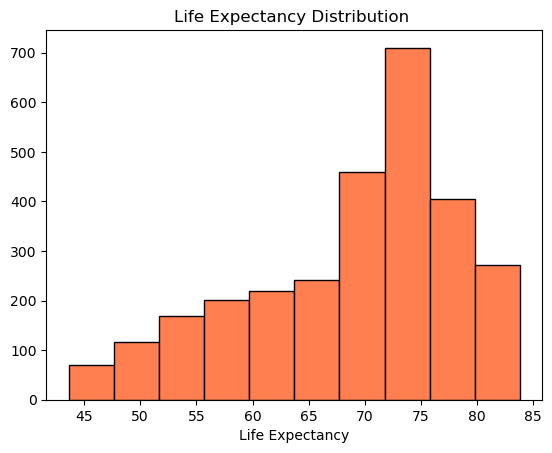

In [207]:
plt.hist(df["life_expectancy"], color= 'coral', edgecolor = "black")
plt.title("Life Expectancy Distribution ")
plt.xlabel("Life Expectancy")

In [208]:
def count_plot(data, x_axis=None ,y_axis=None, hue=None, rotation=0, top=None, ax=None,):
    """Draw a Seaborn countplot ordered by category frequency with bar value labels."""

    if x_axis is None and y_axis is None:
        raise ValueError("Either 'x_axis' or 'y_axis' must be specified.")

    target_col = x_axis if x_axis is not None else y_axis
    order = data[target_col].value_counts().iloc[:top].index # choose the amount of entries you'd like to see

    graph = sns.countplot(
        data=data,
        x=x_axis,
        y=y_axis,
        hue=hue,
        order=order,
        ax=ax,
    )

    for container in graph.containers:
        graph.bar_label(container)

    if x_axis is not None:
        graph.tick_params(axis="x", rotation=rotation)

    return graph

# Feature Selection

## VIF

In [209]:
from statsmodels.api import add_constant

In [210]:
df.columns.to_list()

['country',
 'region',
 'year',
 'infant_deaths',
 'under_five_deaths',
 'adult_mortality',
 'alcohol_consumption',
 'hepatitis_b',
 'measles',
 'bmi',
 'polio',
 'diphtheria',
 'incidents_hiv',
 'gdp_per_capita',
 'population_mln',
 'schooling',
 'economic_status',
 'life_expectancy',
 'thinness_five_nineteen_years']

In [211]:
cols_to_check = [
 'year',
 'infant_deaths',
 'under_five_deaths',
 'adult_mortality',
 'alcohol_consumption',
 'hepatitis_b',
 'measles',
 'bmi',
 'polio',
 'diphtheria',
 'incidents_hiv',
 'gdp_per_capita',
 'population_mln',
 'schooling',
 'thinness_five_nineteen_years']

#  'economic_status'

In [212]:
df_with_const = add_constant(df[cols_to_check])

vif_series = pd.Series(
    [
        variance_inflation_factor(df_with_const.values, i)
        for i in range(df_with_const.shape[1])
    ],
    index=df_with_const.columns,
).drop("const")

print(vif_series.sort_values(ascending=False))

under_five_deaths               59.165281
infant_deaths                   55.820545
diphtheria                      15.114009
polio                           13.945378
adult_mortality                  6.256956
schooling                        4.456012
hepatitis_b                      3.043136
incidents_hiv                    2.748030
bmi                              2.669265
gdp_per_capita                   2.647844
alcohol_consumption              2.090035
thinness_five_nineteen_years     2.080926
measles                          1.685669
population_mln                   1.190387
year                             1.091548
dtype: float64


In [213]:
cols_to_drop = vif_series[vif_series > 5].index.to_list()

In [214]:
cols_to_drop

['infant_deaths',
 'under_five_deaths',
 'adult_mortality',
 'polio',
 'diphtheria']

In [215]:
df = df.drop(columns = cols_to_drop)

In [216]:
df.head()

,country,region,year,alcohol_consumption,hepatitis_b,measles,bmi,incidents_hiv,gdp_per_capita,population_mln,schooling,economic_status,life_expectancy,thinness_five_nineteen_years
0,Turkiye,Middle East,2015,1.32,97,65.0,27.8,0.08,11006.000,56.0725,7.8,0,76.5,4.850
1,Spain,European Union,2015,10.35,97,94.0,26.0,0.09,25742.000,46.4400,9.7,1,82.8,0.550
2,India,Asia,2007,1.57,60,35.0,21.2,0.13,1076.000,56.0725,5.0,0,65.4,15.475
3,Guyana,South America,2006,5.68,93,74.0,25.3,0.79,4146.000,0.7500,7.9,0,67.0,5.600
4,Palestine,Middle East,2012,2.89,97,89.0,27.0,0.08,29268.875,7.9100,12.8,1,81.7,1.150


In [217]:
df["region"].unique()

array(['Middle East', 'European Union', 'Asia', 'South America',
       'Central America and Caribbean', 'Rest of Europe', 'Africa',
       'Oceania', 'North America'], dtype=object)

In [218]:
X = df.drop(columns = ["life_expectancy", "country"])
y = df["life_expectancy"]

In [219]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42) # test out 0.3 after

In [220]:
def stepwise_selection(X, y, threshold_in=0.01, threshold_out=0.05, verbose=True):
    # The function checks p-values (statistical significance of features) - lower is better
    included = []  # list of features we keep
    while True:
        changed = False

        # forward step: try adding each excluded feature and pick the most significant one
        excluded = list(set(X.columns) - set(included))
        new_pval = pd.Series(index=excluded, dtype='float64')
        for new_column in excluded:
            model = sm.OLS(y, sm.add_constant(pd.DataFrame(X[included + [new_column]]))).fit()
            new_pval[new_column] = model.pvalues[new_column]
        best_pval = new_pval.min()
        # add the feature with the lowest (best) p-value if it's under the threshold
        if best_pval < threshold_in:
            best_feature = new_pval.idxmin()
            included.append(best_feature)
            changed = True
            if verbose:
                print('Add  {:30} with p-value {:.6}'.format(best_feature, best_pval))

        # backward step: drop any feature that became insignificant after the forward step
        model = sm.OLS(y, sm.add_constant(pd.DataFrame(X[included]))).fit()
        # use all coefs except intercept
        pvalues = model.pvalues.iloc[1:]
        worst_pval = pvalues.max()  # null if pvalues is empty
        # if a feature's p-value exceeds the upper threshold, drop it
        if worst_pval > threshold_out:
            changed = True
            worst_feature = pvalues.idxmax()
            included.remove(worst_feature)
            if verbose:
                print('Drop {:30} with p-value {:.6}'.format(worst_feature, worst_pval))

        if not changed:
            break

    return included

# Encoding

In [221]:
# ohe = OneHotEncoder(handle_unknown = "ignore", sparse_output=False)

# ohe.fit(X_train[["region"]])
# X_train_encoded = ohe.transform(X_train[["region"]])

# X_test_encoded = ohe.transform(X_test[["region"]])

In [222]:
import pandas as pd

X_train_encoded = pd.get_dummies(X_train, columns=["region"], drop_first=True, dtype=int)

X_test_encoded = pd.get_dummies(X_test, columns=["region"], drop_first=True, dtype=int)

X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join="left", axis=1, fill_value=0)

# Scaling

In [223]:
scaler = StandardScaler()

X_train_scaled_encoded = pd.DataFrame(scaler.fit_transform(X_train_encoded), columns=X_train_encoded.columns, index=X_train_encoded.index,)

X_test_scaled_encoded = pd.DataFrame(scaler.transform(X_test_encoded), columns=X_test_encoded.columns, index=X_test_encoded.index,)

# Stepwise Selection

In [224]:
selected_features = stepwise_selection(X_train_scaled_encoded, y_train, threshold_in=0.01, threshold_out=0.05, verbose=True)

X_train_final = X_train_scaled_encoded[selected_features]
X_test_final = X_test_scaled_encoded[selected_features]

Add  incidents_hiv                  with p-value 0.0
Add  schooling                      with p-value 4.2421e-269
Add  gdp_per_capita                 with p-value 3.29019e-98
Add  region_Central America and Caribbean with p-value 1.25705e-63
Add  hepatitis_b                    with p-value 1.90277e-49
Add  region_South America           with p-value 2.7733e-40
Add  year                           with p-value 4.00243e-13
Add  population_mln                 with p-value 1.64973e-08
Add  bmi                            with p-value 2.24581e-06
Add  region_Rest of Europe          with p-value 0.000146993
Add  region_European Union          with p-value 9.64958e-05
Add  region_Asia                    with p-value 2.70371e-09
Add  alcohol_consumption            with p-value 7.70543e-05
Add  region_North America           with p-value 0.000826755
Add  region_Middle East             with p-value 0.000371094
Add  region_Oceania                 with p-value 2.17018e-07


# Linear Regression

In [225]:
model = LinearRegression()
model.fit(X_train_final, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [226]:
y_train_pred = model.predict(X_train_final)
y_test_pred = model.predict(X_test_final)

In [227]:
mae = mean_absolute_error(y_test, y_test_pred)
print(mae)

2.7822024376596413


In [228]:
mse = mean_squared_error(y_test, y_test_pred)
print(mse)

13.611963042592093


In [229]:
rmse = root_mean_squared_error(y_test, y_test_pred)
print(rmse)

3.6894393940803654
